In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [5]:
df = pd.DataFrame(pd.read_csv(' https://itv-contentbucket.s3.ap-south-1.amazonaws.com/Exams/ML/PCA/heart_disease.csv'))
df

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [6]:
x = df.drop('target', axis = 1)
y = df['target']

In [11]:
scaler = StandardScaler()
for col in x.columns:
    x[col] = scaler.fit_transform(x[[col]])
x.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,0.952197,0.681005,1.973123,0.763956,-0.256334,2.394438,-1.005832,0.015443,-0.696631,1.087338,-2.274579,-0.714429,-2.148873
1,-1.915313,0.681005,1.002577,-0.092738,0.072199,-0.417635,0.898962,1.633471,-0.696631,2.122573,-2.274579,-0.714429,-0.512922
2,-1.474158,-1.468418,0.032031,-0.092738,-0.816773,-0.417635,-1.005832,0.977514,-0.696631,0.310912,0.976352,-0.714429,-0.512922
3,0.180175,0.681005,0.032031,-0.663867,-0.198357,-0.417635,0.898962,1.239897,-0.696631,-0.206705,0.976352,-0.714429,-0.512922
4,0.290464,-1.468418,-0.938515,-0.663867,2.082050,-0.417635,0.898962,0.583939,1.435481,-0.379244,0.976352,-0.714429,-0.512922


#### Model Training

In [13]:
pca = PCA()

x_pca = pca.fit_transform(x)
x_pca

array([[ 0.62411073,  2.32127028,  2.47467255, ..., -0.55811461,
         0.40407485, -0.42022097],
       [-0.45598798, -0.95735098,  1.1395948 , ..., -0.4921327 ,
         0.23225951, -0.27427359],
       [-1.82880491,  0.04288477, -0.45222878, ...,  0.36372499,
         0.17797717,  1.10955334],
       ...,
       [ 2.45900545,  0.47826191,  2.20821632, ..., -1.46340968,
         0.91844747,  0.75068625],
       [ 1.76275536, -2.33681621,  0.45475258, ...,  0.376824  ,
        -0.07554132, -0.34956711],
       [-0.86005677,  1.06851556, -0.69007429, ...,  0.08023982,
         0.31320761, -1.17838479]], shape=(303, 13))

In [14]:
explained_variance = pca.explained_variance_ratio_
print("Explained Variance Ratio: ",explained_variance)

Explained Variance Ratio:  [0.21254053 0.11820708 0.09406418 0.09085735 0.07861281 0.07461661
 0.06636692 0.05968811 0.05530196 0.04781309 0.04077729 0.03254941
 0.02860467]


In [16]:
cum_var = np.cumsum(explained_variance)
print("Incumulative Variance: ",cum_var)

Incumulative Variance:  [0.21254053 0.33074761 0.42481179 0.51566913 0.59428194 0.66889855
 0.73526547 0.79495357 0.85025553 0.89806862 0.93884591 0.97139533
 1.        ]


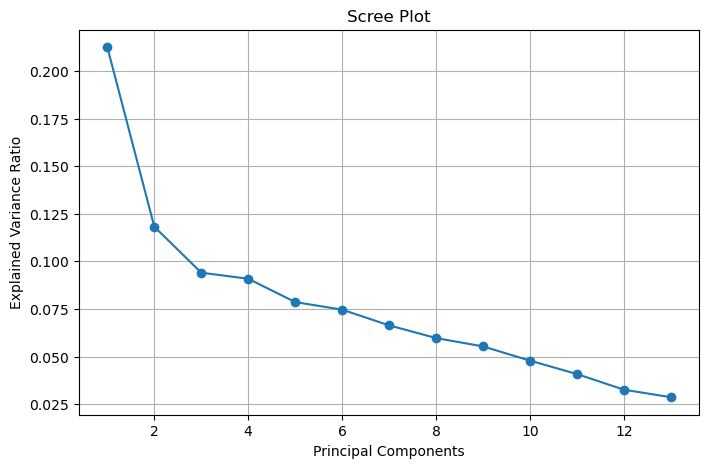

In [17]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(explained_variance)+1),
    explained_variance,
    marker='o'
)

plt.xlabel('Principal Components')
plt.ylabel('Explained Variance Ratio')
plt.title('Scree Plot')
plt.grid(True)

plt.show()

In [22]:
pca = PCA(n_components=2)

xpca = pca.fit_transform(x)

print("Original Shape :", x.shape)
print("Reduced Shape  :", xpca.shape)

Original Shape : (303, 13)
Reduced Shape  : (303, 2)


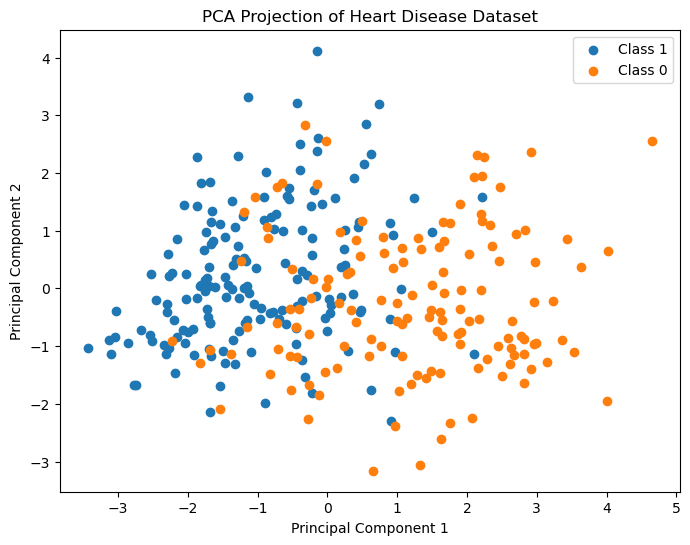

In [23]:
pca_df = pd.DataFrame(
    xpca,
    columns=['PC1','PC2']
)

pca_df['target'] = y

plt.figure(figsize=(8,6))

for cls in pca_df['target'].unique():
    
    data = pca_df[pca_df['target']==cls]
    
    plt.scatter(
        data['PC1'],
        data['PC2'],
        label=f'Class {cls}'
    )

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA Projection of Heart Disease Dataset')
plt.legend()

plt.show()
